## Анализ и прогнозирование временных рядов методами искусственного интеллекта

### **Практическая работа 3. Поиск аномалий во временных рядах.**


#### **3.1 Поиск диссонансов с помощью алгоритма HotSAX**

##### 3.1.1 Загрузка и подготовка данных

В данной будет использоваться временной ряд, состоящий из показаний акселерометра. 
Анализируемый временной ряд, описывает две активности человека - бег и шаг.


In [1]:
# При необходимости установить зависимости в используемое ядро:
# %pip install -r requirements.txt
# Установка не выполняется автоматически при запуске всех ячеек.

In [2]:
import random
import numpy as np
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
from importlib.metadata import version
from IPython.display import display

np.random.seed(42)
random.seed(42)
plt.style.use('default')
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white',
                     'savefig.facecolor': 'white', 'text.color': 'black',
                     'axes.labelcolor': 'black', 'xtick.color': 'black',
                     'ytick.color': 'black', 'font.size': 10})
print('NumPy', version('numpy'), '| Numba', version('numba'),
      '| STUMPY', version('stumpy'))

NumPy 2.4.6 | Numba 0.67.0 | STUMPY 1.14.1


In [3]:
# Поиск рабочей папки при запуске из каталога лабораторной или корня репозитория.
candidates = [Path.cwd(), Path.cwd() / 'practice' / '03 Discords']
lab_dir = next((p for p in candidates if (p / 'datasets' / 'walk_run.txt').is_file()), None)
if lab_dir is None:
    raise FileNotFoundError('Откройте ноутбук из папки 03 Discords или корня репозитория')
import os
os.chdir(lab_dir)
if str(lab_dir) not in sys.path:
    sys.path.insert(0, str(lab_dir))
dataset_dir_path = Path('datasets')
walk_run = np.loadtxt(dataset_dir_path / 'walk_run.txt')[3000:4000].astype(float)
assert walk_run.shape == (1000,) and np.isfinite(walk_run).all()
data = walk_run
size_sub = 50
print('Длина фрагмента:', len(data), '| длина окна:', size_sub,
      '| окон:', len(data) - size_sub + 1)

Длина фрагмента: 1000 | длина окна: 50 | окон: 951


В середине временного ряда происходит смена активности (бег заменяет шаг). Нетипичным поведением, которое мы могли бы назвать диссонансами в данном ряде выступает небольшой участок между активностями, когда человек плавно увеличивает скорость шага до бега. В ходе данной работе наша задача выделить с помощью различных алгоритмов границы нашего диссонанса.

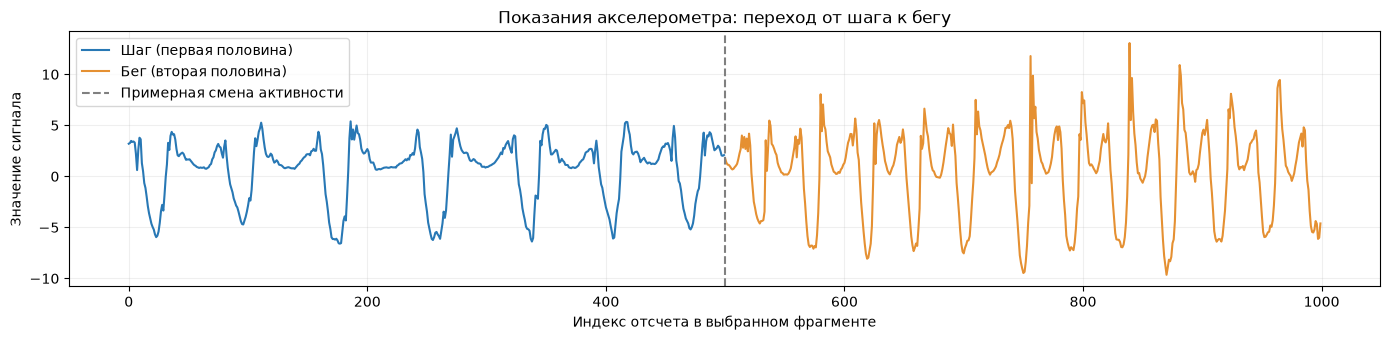

In [4]:
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(np.arange(500), data[:500], label='Шаг (первая половина)', color='#2878b5')
ax.plot(np.arange(500, len(data)), data[500:], label='Бег (вторая половина)', color='#e59032')
ax.axvline(500, color='gray', linestyle='--', label='Примерная смена активности')
ax.set(title='Показания акселерометра: переход от шага к бегу',
       xlabel='Индекс отсчета в выбранном фрагменте', ylabel='Значение сигнала')
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()

In [5]:
result={}
times={}

##### 3.1.2 Реализация полного перебора

Приводится пример кода для нахождения топ 5 диссонансов с помощью реализации полного беребора.
Вам необходимо добавить код для сбора времени обработки данных.

In [6]:
from modules.saxpy.discord import find_discords_brute_force
from modules.analysis import measure_search, result_table, plot_discords, plot_times

# Прогрев Numba не входит в измерение времени.
find_discords_brute_force(data[:100], 10, 1)
discords_brute_force, times['Полный перебор'] = measure_search(
    find_discords_brute_force, data, size_sub, 5)
result['Полный перебор'] = discords_brute_force
display(result_table(discords_brute_force, offset=3000))
print('Время, с:', times['Полный перебор'])

,Начало окна,Индекс в исходном файле,Расстояние до ближайшего соседа
0,477,3477,5.881009
1,412,3412,5.327043
2,195,3195,3.394266
3,577,3577,3.355544
4,278,3278,3.109594


Время, с: 0.058519699989119545


##### 3.1.3 HotSAX

Используя [реализацию](https://github.com/seninp/saxpy/blob/master/saxpy/hotsax.py) найдите топ 5 диссонансов ряда.
Произведите замер времени работы.

In [7]:
from modules.saxpy.hotsax import find_discords_hotsax

discords_hotsax, times['HotSAX'] = measure_search(
    find_discords_hotsax, data, size_sub, 5)
result['HotSAX'] = discords_hotsax
display(result_table(discords_hotsax, offset=3000))
np.testing.assert_allclose(discords_hotsax, discords_brute_force, rtol=1e-9, atol=1e-8)
print('HotSAX и перебор нашли одинаковые пять диссонансов.')

,Начало окна,Индекс в исходном файле,Расстояние до ближайшего соседа
0,477,3477,5.881009
1,412,3412,5.327043
2,195,3195,3.394266
3,577,3577,3.355544
4,278,3278,3.109594


HotSAX и перебор нашли одинаковые пять диссонансов.


##### 3.1.4 Визаулизация

Вам необходимо реализовать код позволяющий:
1. Вывести на одном графике ряд и его диссонансы
2. Столбчатую диаграмму времени работы обоих алгоритмов
   
Постройте графики для обоих алгоритмов и сравните полученные результаты.

Пример графика:

![first_graf](pics/fig_ex_1.png)

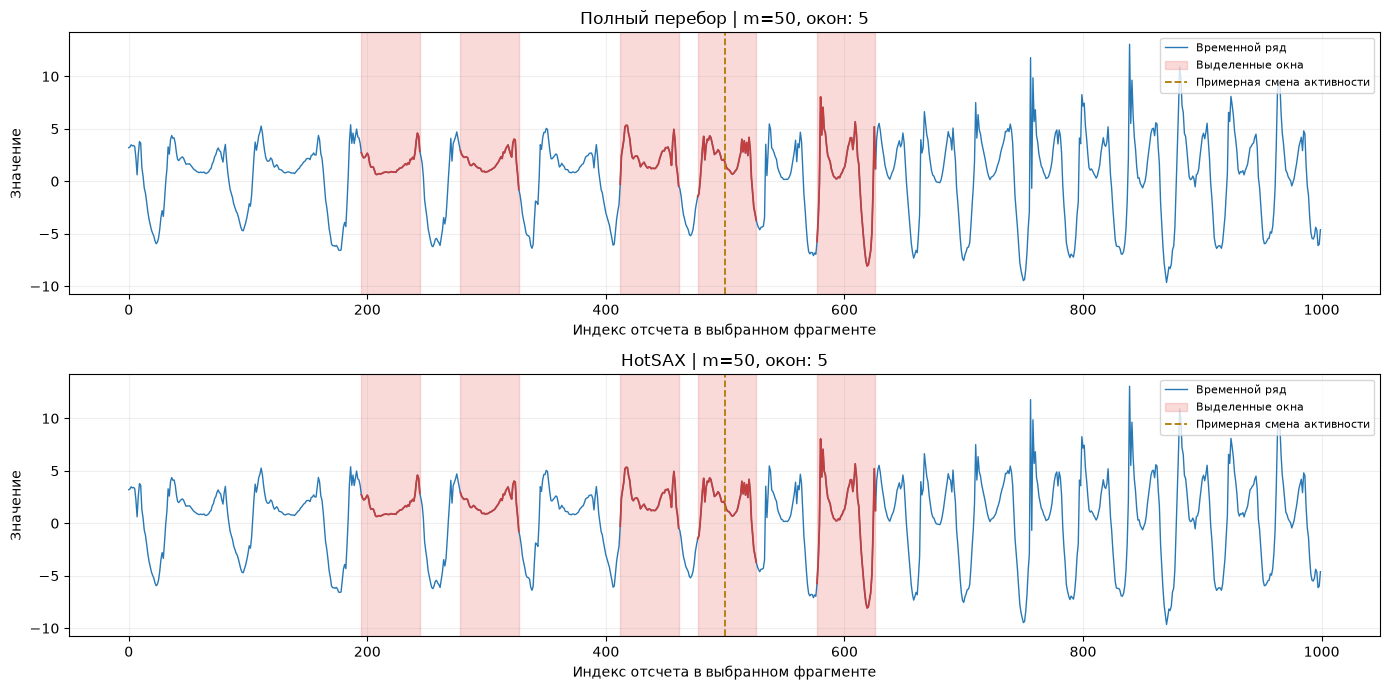

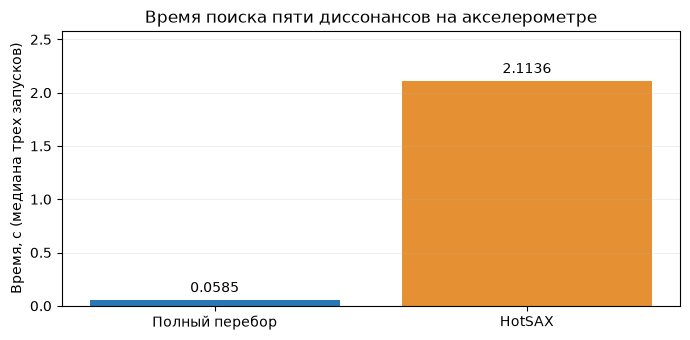

,Алгоритм,"Медиана времени, с"
0,Полный перебор,0.058520
1,HotSAX,2.113583


Отношение времени перебора ко времени HotSAX: 0.028


In [8]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
for ax, (name, found) in zip(axes, result.items()):
    plot_discords(data, found[:, 0], size_sub, name, ax=ax, boundary=500)
fig.tight_layout()
plt.show()
plot_times(times, 'Время поиска пяти диссонансов на акселерометре')
display(pd.DataFrame({'Алгоритм': list(times), 'Медиана времени, с': list(times.values())}))
print(f"Отношение времени перебора ко времени HotSAX: {times['Полный перебор'] / times['HotSAX']:.3f}")

In [9]:
# Основные совпадения находятся у перехода, но top-5 включает и другие редкие окна.
# Большое расстояние до ближайшего НЕПЕРЕСЕКАЮЩЕГОСЯ соседа означает более редкую форму.
# HotSAX сначала проверяет редкие SAX-слова, затем уточняет точные ED.
# Время — медиана трех запусков на одинаковых данных с seed=42.
# Перебор использует Numba и один раз вычисляет точный профиль; это не чистый Python.
# Поэтому результат сравнения реализаций не обязан показывать выигрыш HotSAX.

##### 3.1.5 Такси NY

Произведите поиск диссонансов с помощью обоих алгоритмов на наборе данных, содержащим информацию о среднем числе пассажиров в NY. Отобразите найденные диссонансы обоими алгоритмами. 

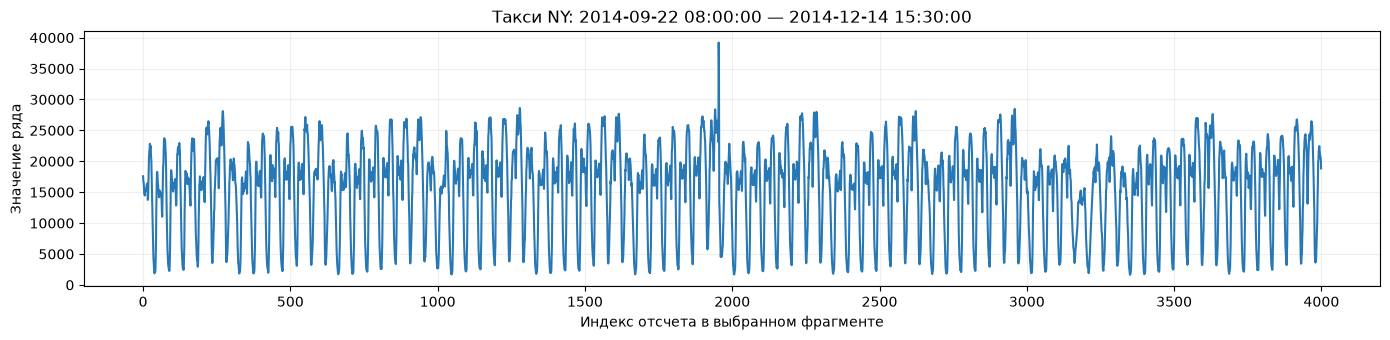

In [10]:
taxi_frame = pd.read_csv(dataset_dir_path / 'nyc_taxi.csv', parse_dates=['timestamp'])
taxi_fragment = taxi_frame.iloc[4000:8000].reset_index(drop=True)
nyc_taxi = taxi_fragment['value'].to_numpy(dtype=float)
assert len(nyc_taxi) == 4000 and np.isfinite(nyc_taxi).all()
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(nyc_taxi, color='#2878b5')
ax.set(title=f"Такси NY: {taxi_fragment.timestamp.iloc[0]} — {taxi_fragment.timestamp.iloc[-1]}",
       xlabel='Индекс отсчета в выбранном фрагменте', ylabel='Значение ряда')
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

Полный перебор


,Начало окна,Индекс в исходном файле,Расстояние до ближайшего соседа
0,1910,5910,3.526815
1,3120,7120,3.402332
2,3183,7183,2.642041
3,3237,7237,2.229228
4,963,4963,1.611528


HotSAX


,Начало окна,Индекс в исходном файле,Расстояние до ближайшего соседа
0,1910,5910,3.526815
1,3120,7120,3.402332
2,3183,7183,2.642041
3,3237,7237,2.229228
4,963,4963,1.611528


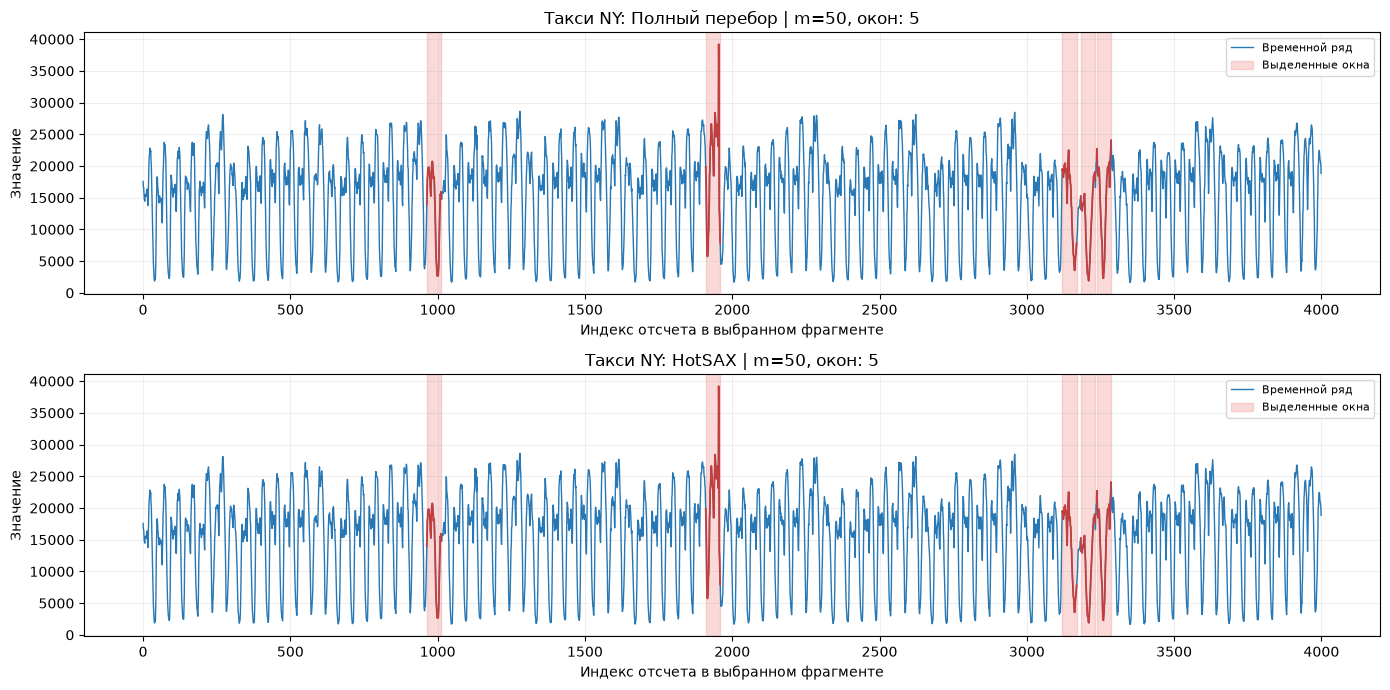

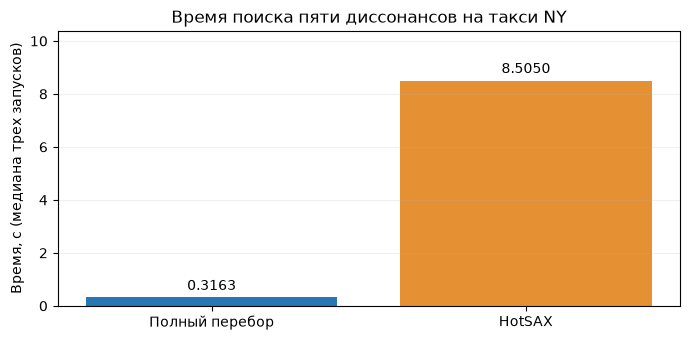

Оба алгоритма дали одинаковые индексы и расстояния на такси NY.
Отношение времени перебора ко времени HotSAX: 0.037


In [11]:
taxi_result, taxi_times = {}, {}
for name, search in [('Полный перебор', find_discords_brute_force), ('HotSAX', find_discords_hotsax)]:
    taxi_result[name], taxi_times[name] = measure_search(search, nyc_taxi, size_sub, 5)
    print(name)
    display(result_table(taxi_result[name], offset=4000))
np.testing.assert_allclose(taxi_result['Полный перебор'], taxi_result['HotSAX'], rtol=1e-9, atol=1e-8)
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
for ax, (name, found) in zip(axes, taxi_result.items()):
    plot_discords(nyc_taxi, found[:, 0], size_sub, f'Такси NY: {name}', ax=ax)
fig.tight_layout()
plt.show()
plot_times(taxi_times, 'Время поиска пяти диссонансов на такси NY')
print('Оба алгоритма дали одинаковые индексы и расстояния на такси NY.')
print(f"Отношение времени перебора ко времени HotSAX: {taxi_times['Полный перебор'] / taxi_times['HotSAX']:.3f}")

#### **3.2 Поиск диссонансов с помощью алгоритма DRAG**

In [12]:
# В текущем окружении проверена stumpy==1.14.1.
# Старая stumpy==1.11.1 несовместима с используемой версией NumPy.
# При необходимости: %pip install -r requirements.txt

In [13]:
import stumpy
from stumpy import core, config
from modules.drag import DRAG, find_candidates, refine_candidates

# В DRAG сохраняется радиус исключения из шаблона: ceil(m / 4).
print('Знаменатель зоны исключения STUMPY:', config.STUMPY_EXCL_ZONE_DENOM)
DRAG(walk_run[:100], 10, 1)  # прогрев компиляции вне замеров

Знаменатель зоны исключения STUMPY: 4


([71, 1, 59, 18, 32, 75, 40, 5],
 [2.6997789875917473,
  2.6327706204226864,
  2.1035350351794007,
  2.015711639470001,
  1.6571853689859555,
  1.534332961340135,
  1.4895139843232488,
  1.3004032162144625],
 [32, 73, 18, 90, 70, 4, 46, 77])

Как мы помним из лекций:

**Диапазонный диссонанс** – подпоследовательность ряда, расстояние от которой до ее ближайшего соседа не ниже заданного порога. 

Основными параметрами при поисках диссонансов являются:
- $m$ - длина диссонанса
- $r$ - пороговое значение расстояния подпоследовательности ряда, до его ближайшего соседа


In [14]:
from modules.drag import find_candidates, DRAG


Для поиска диссонансов в данной части практической работы мы воспользуемся алгоритмом **DRAG (Discord Range Aware Gathering)**.
Для начала воспользуемся данным алгоритмом, чтобы найти диссонансы в наборе данных содержащем активность человека.

In [15]:
data = walk_run

Длину искомого диссонанса, как и для предыдущих алгоритмов, мы установим равно 50 точек.
Пороговое значение мы установим равным большим, чтобы узнать, как алгоритм отреагирует на большие значения данного параметра.

In [16]:
m, r = 50, 10
drag_high = DRAG(data, m, r)
print('Количество найденных диссонансов при r=10:', len(drag_high[0]))
assert len(drag_high[0]) == 0

Количество найденных диссонансов при r=10: 0


Как вы можете видеть мы установили слишком большое пороговое значение, алгоритму не удалось выделить ни одного диссонанса. Попробуем уменьшить пороговое значение до 1, чтобы улучшить результат. 

Количество найденных диссонансов при r=1: 50


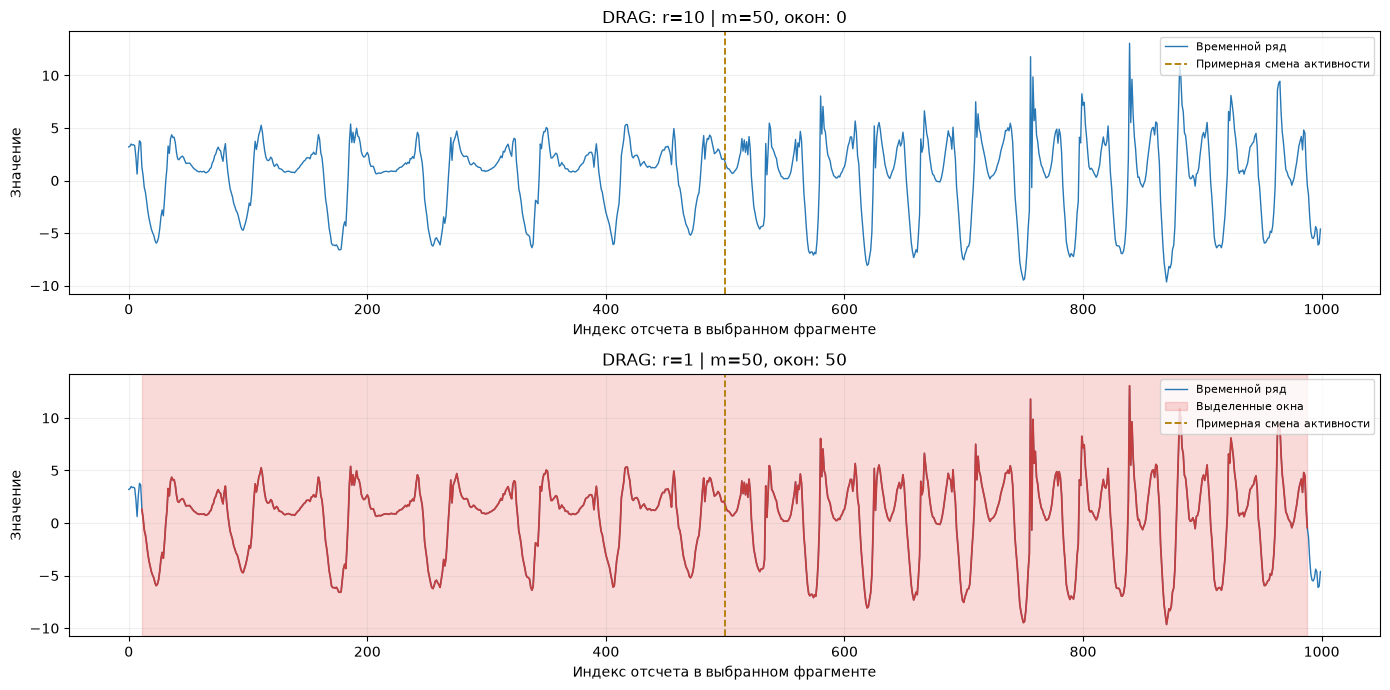

In [17]:
m, r = 50, 1
drag_low = DRAG(data, m, r)
print('Количество найденных диссонансов при r=1:', len(drag_low[0]))
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
plot_discords(data, drag_high[0], m, 'DRAG: r=10', ax=axes[0], boundary=500)
plot_discords(data, drag_low[0], m, 'DRAG: r=1', ax=axes[1], boundary=500)
fig.tight_layout()
plt.show()

При r=1 выделено 50 окон: низкий порог допускает множество сравнительно обычных фрагментов.
При r=10 диссонансов нет, поскольку даже наиболее редкое окно не достигает такого расстояния
до ближайшего соседа. Это показывает необходимость подбора порога, а не ошибку алгоритма.

Произведите подобные эксперименты с набором данных такси NY. Постройте графики демонстрирующие найденные диссонансы. Пример Графика:
![second-graph](pics/fig_ex_2.png)

,m,r,Количество окон
0,50,10,0
1,50,1,42
2,50,3,4


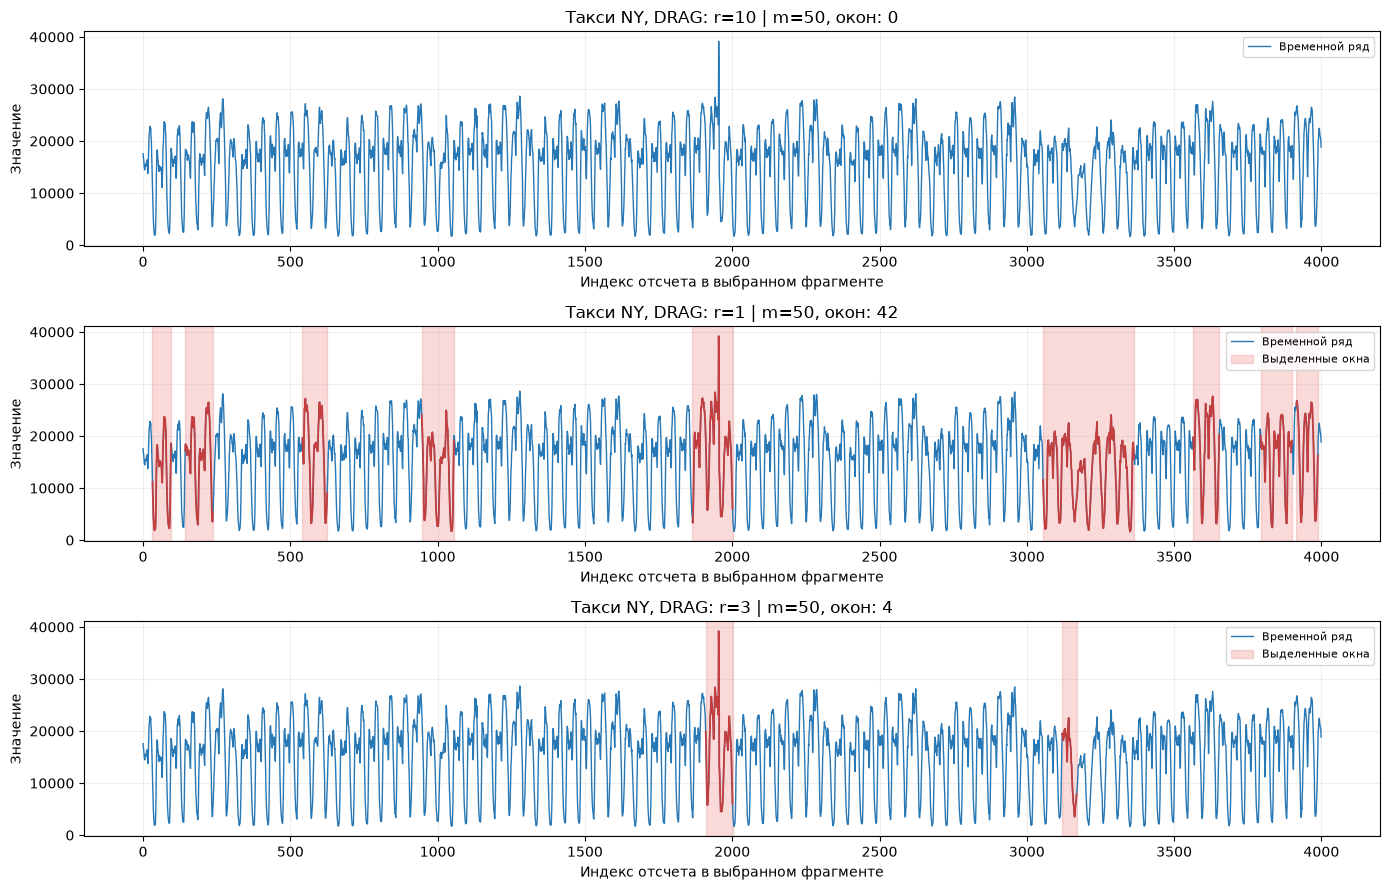

In [18]:
taxi_threshold_results = {threshold: DRAG(nyc_taxi, 50, threshold) for threshold in [10, 1, 3]}
display(pd.DataFrame([{'m': 50, 'r': threshold, 'Количество окон': len(found[0])}
                      for threshold, found in taxi_threshold_results.items()]))
fig, axes = plt.subplots(3, 1, figsize=(14, 9))
for ax, (threshold, found) in zip(axes, taxi_threshold_results.items()):
    plot_discords(nyc_taxi, found[0], 50, f'Такси NY, DRAG: r={threshold}', ax=ax)
fig.tight_layout()
plt.show()

Чтобы разобраться, почему так происходит и как работает данный алгоритм, ниже мы реализуем все этапы алгоритма DRAG.

Как мы помним из лекций алгоритм DRAG содержит два этапа:

1. Отбор - За одно сканирование ряда сформировать множество кандидатов в диссонансы.
2. Очистка - За одно сканирование ряда отбросить кандидатов, которые являются ложными диссонансами.

##### 3.2.1 Отбор кандидатов

Первым этапом обработки данных является отбор множества потенциальных кандидатов. Мы выбираем из всего множества подпоследовательностей ряда такие, для которых расстояние до правых ближайших соседей больше параметра $r$.

In [19]:
# Возвращаемся к акселерометру для поэтапного выполнения DRAG.
data, m, r = walk_run, 50, 3

In [20]:
T, M_T, Σ_T, *_ = core.preprocess(data, m)
is_cands = find_candidates(T, m, M_T, Σ_T, r, init_cands=None, right=True)
right_candidates = is_cands.copy()
cand_index = np.flatnonzero(is_cands)

In [21]:
print(f'Отбор: {len(cand_index)} из {len(is_cands)} окон ({is_cands.mean():.2%})')

Отбор: 207 из 951 окон (21.77%)


После правого прохода осталось 207 из 951 окон (21,77%). У них нет правого нетривиального
соседа ближе r=3. Это еще не окончательные диссонансы: у части окон может быть близкий сосед
слева. У последних окон правых соседей может не быть вообще, поэтому они также проходят отбор.

Сформируйте график найденных диссонансов

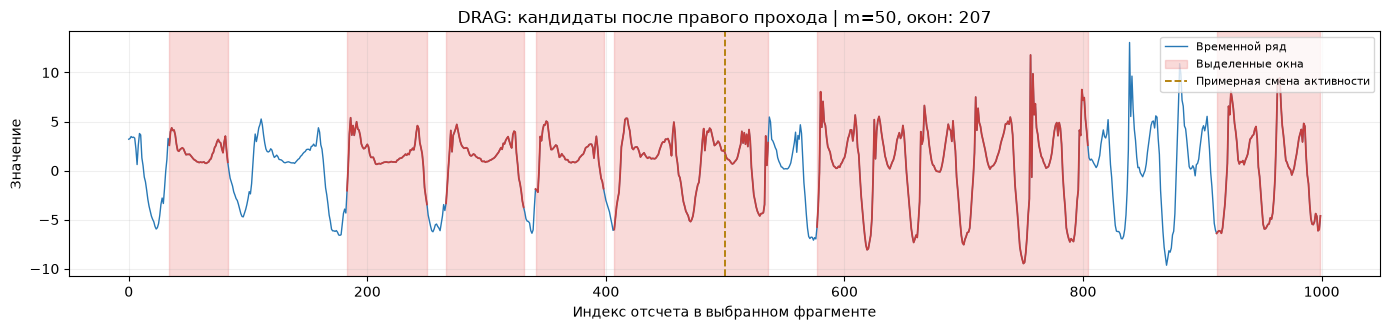

<Axes: title={'center': 'DRAG: кандидаты после правого прохода | m=50, окон: 207'}, xlabel='Индекс отсчета в выбранном фрагменте', ylabel='Значение'>

In [22]:
plot_discords(data, cand_index, m, 'DRAG: кандидаты после правого прохода', boundary=500)

##### 3.2.2 Очистка кандидатов
Теперь проверяются левые нетривиальные соседи. Если слева существует окно с расстоянием
меньше r, кандидат удаляется. Маска очищенных кандидатов является подмножеством исходной.

In [23]:
is_cands = find_candidates(T, m, M_T, Σ_T, r, init_cands=is_cands, right=False)
clean_candidates = is_cands.copy()
cands = np.flatnonzero(is_cands)
assert np.all(~is_cands | right_candidates)

In [24]:
print(f'Очистка: {len(cands)} из {len(is_cands)} окон ({is_cands.mean():.2%})')

Очистка: 29 из 951 окон (3.05%)


Сформируйте график найденных диссонансов

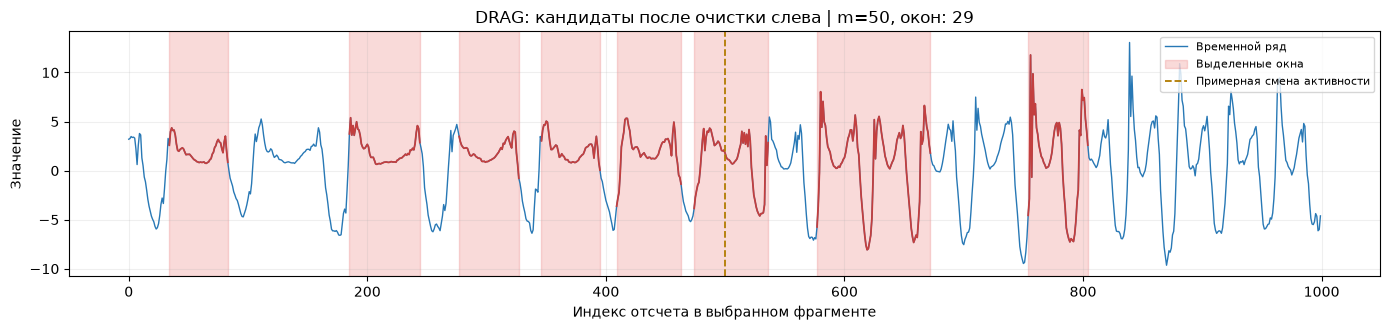

<Axes: title={'center': 'DRAG: кандидаты после очистки слева | m=50, окон: 29'}, xlabel='Индекс отсчета в выбранном фрагменте', ylabel='Значение'>

In [25]:
plot_discords(data, cands, m, 'DRAG: кандидаты после очистки слева', boundary=500)

После очистки осталось 29 окон (3,05% от 951 возможного). Их расстояния до всех
нетривиальных соседей не ниже r=3. Многие кандидаты расположены близко друг к другу;
на следующем шаге вычисляются точные расстояния и исключаются соседние копии результата.

In [26]:
discords_idx, discords_dist, discords_nn_idx = refine_candidates(T, m, M_T, Σ_T, is_cands)
print(f'После уточнения: {len(discords_idx)} окон ({len(discords_idx) / len(is_cands):.2%})')
staged_result = (discords_idx, discords_dist, discords_nn_idx)

После уточнения: 9 окон (0.95%)


Сформируйте график найденных диссонансов

,Начало,Расстояние,Ближайший сосед
0,477,5.881009,701
1,412,5.327043,346
2,195,3.394266,112
3,578,3.264117,709
4,278,3.109594,115
5,623,3.092187,754
6,755,3.087896,796
7,34,3.082834,346
8,346,3.082834,34


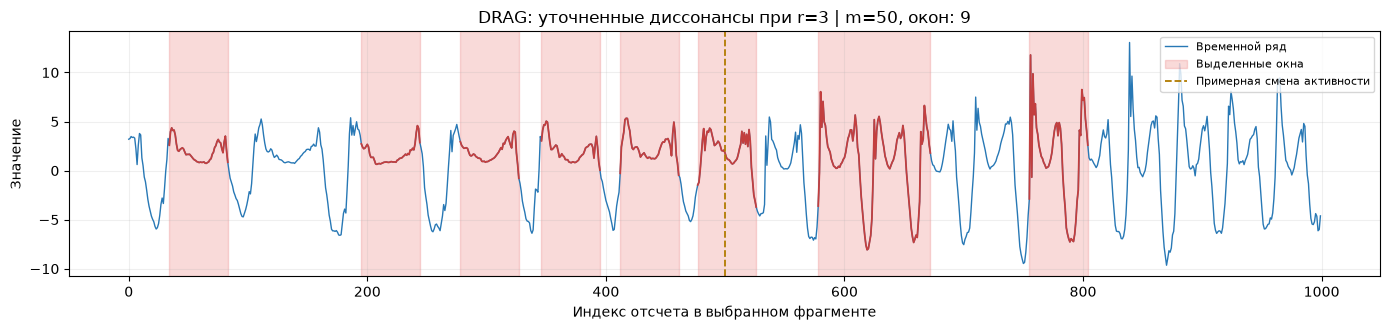

Поэтапное выполнение совпало с полным вызовом DRAG.


In [27]:
display(pd.DataFrame({'Начало': discords_idx, 'Расстояние': discords_dist,
                      'Ближайший сосед': discords_nn_idx}))
plot_discords(data, discords_idx, m, 'DRAG: уточненные диссонансы при r=3', boundary=500)
complete_result = DRAG(data, m, r)
for staged, complete in zip(staged_result, complete_result):
    np.testing.assert_allclose(staged, complete, atol=1e-8)
radius = int(np.ceil(m / config.STUMPY_EXCL_ZONE_DENOM))
assert all(abs(i-j) > radius for i, j in zip(discords_idx, discords_nn_idx))
assert all(distance >= r - 1e-8 for distance in discords_dist)
print('Поэтапное выполнение совпало с полным вызовом DRAG.')

##### 3.2.3 Подбор параметров

Реализуйте перебор параметров $m$ и $r$. Подберете параметры таким образом, чтобы алгоритм обнаружил только те диссонансы, которые связаны со сменой активности. Сделайте вывод о том, как эти параметры влияют на качество работы модели.
Подберите оптимальные параметры алгоритма для набора данных такси NY. 
Визуализируйте результаты для разных комбинаций. Сделайте выводы.


Акселерометр: число окон для каждой комбинации


r,2,3,4,5,10
m,,,,,
30,14,1,0,0,0
40,15,3,1,0,0
50,24,9,2,2,0
75,32,22,4,1,0
100,29,24,15,2,0


Выбрано для акселерометра: m=40, r=4.0; начала окон: [485]


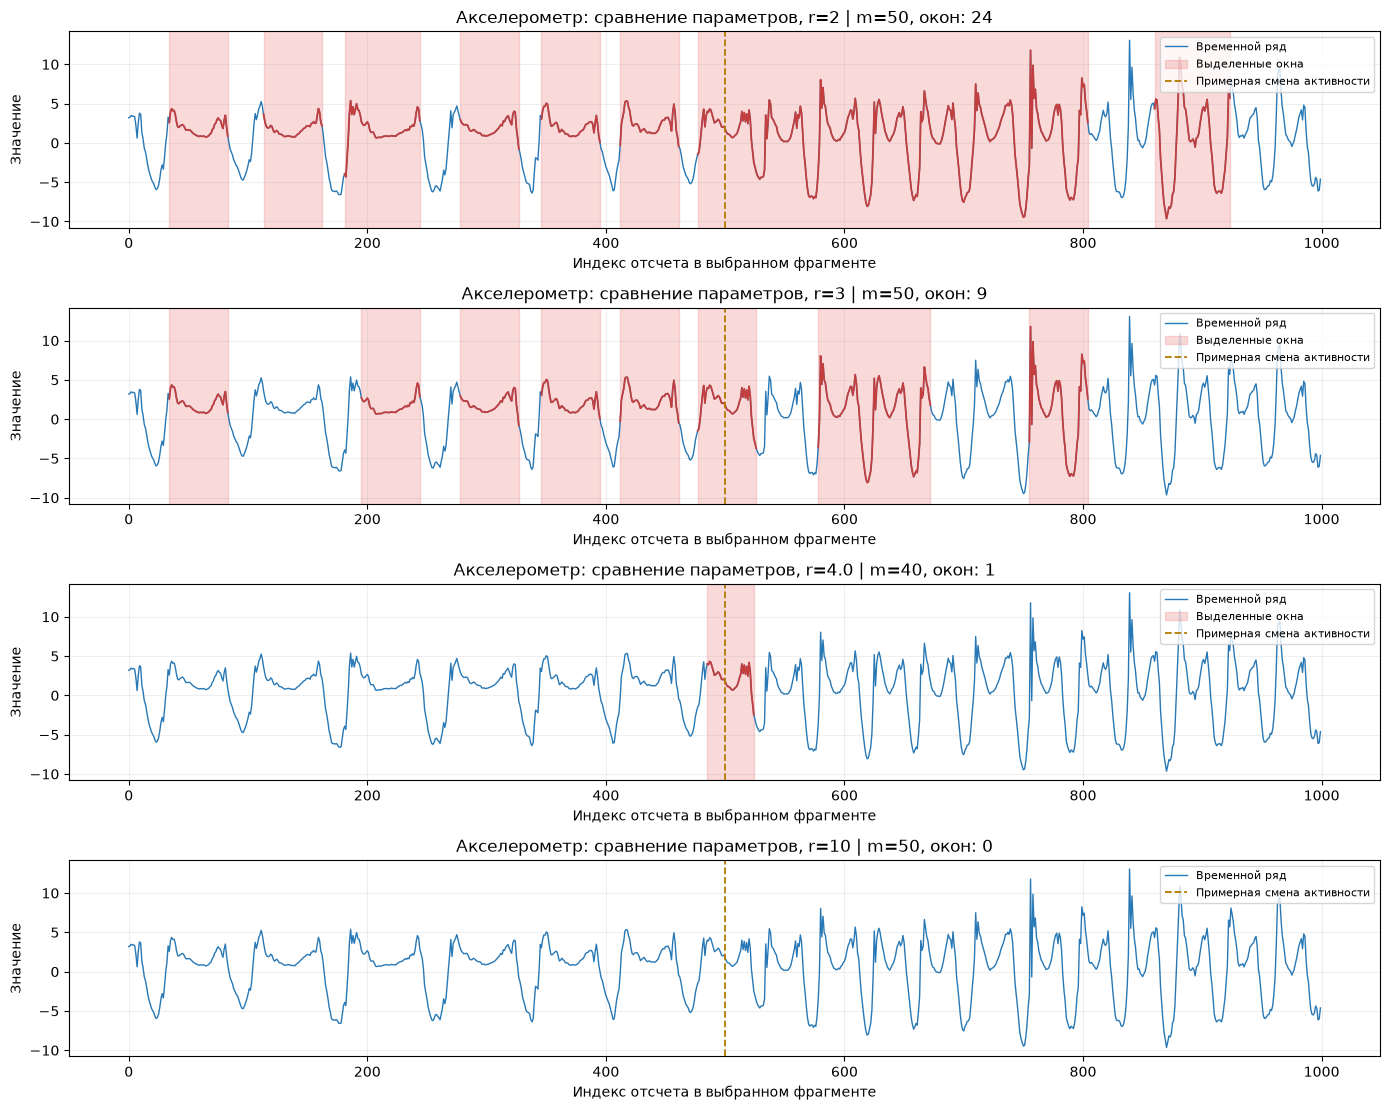

Такси NY: число окон для каждой комбинации


r,1,3,5,7
m,,,,
24,77,3,0,0
48,39,3,0,0
96,73,9,2,0


,Начало,Расстояние,Дата начала,Дата конца
0,3105,5.862946,2014-11-26 00:30:00,2014-11-28 00:00:00
1,3142,5.360657,2014-11-26 19:00:00,2014-11-28 18:30:00


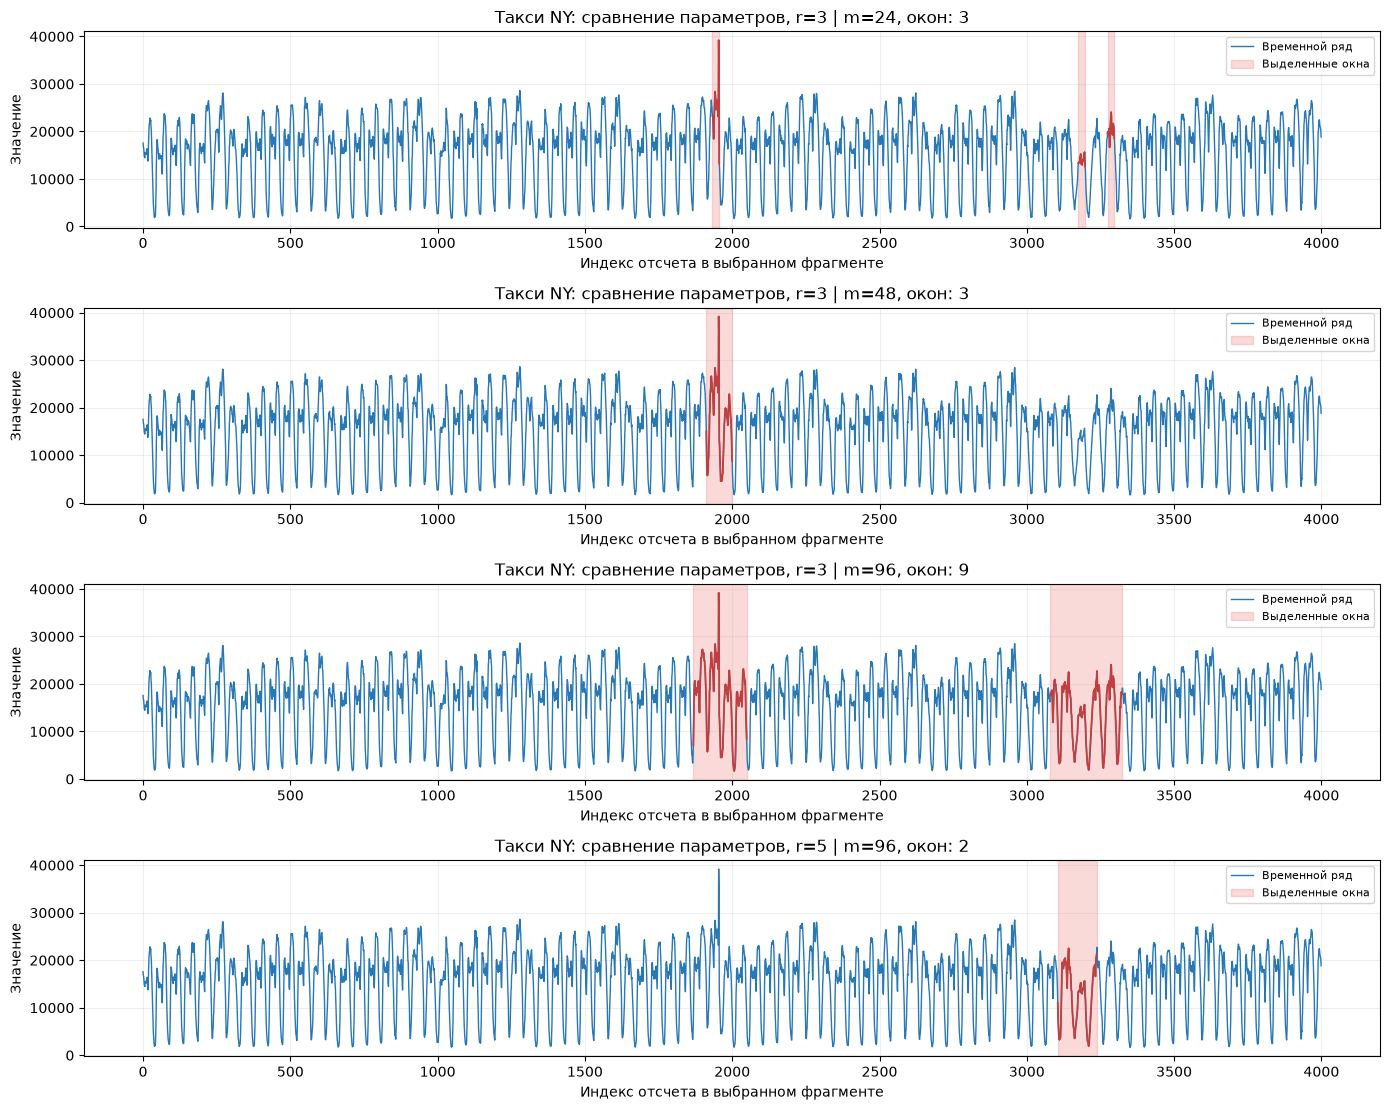

In [28]:
from modules.analysis import parameter_grid, plot_parameter_examples

walk_grid, walk_settings = parameter_grid(
    walk_run, lengths=[30, 40, 50, 75, 100], thresholds=[2, 3, 4, 5, 10], boundary=500)
print('Акселерометр: число окон для каждой комбинации')
display(walk_grid.pivot(index='m', columns='r', values='Количество окон'))
# Учебный критерий: все найденные окна пересекают известную примерную границу 500.
# Затем выбирается наименьшее число окон, при равенстве — m ближе к исходным 50.
eligible = walk_grid[walk_grid['Только смена активности']].copy()
eligible['Отклонение m от 50'] = (eligible['m'] - 50).abs()
chosen_walk = eligible.sort_values(['Количество окон', 'Отклонение m от 50', 'r']).iloc[0]
walk_m, walk_r = int(chosen_walk['m']), float(chosen_walk['r'])
walk_best = walk_settings[walk_m, walk_r]
print(f'Выбрано для акселерометра: m={walk_m}, r={walk_r}; начала окон: {walk_best[0]}')
assert walk_best[0] and all(i <= 500 < i + walk_m for i in walk_best[0])
plot_parameter_examples(walk_run, walk_settings, [(50, 2), (50, 3), (walk_m, walk_r), (50, 10)],
                        'Акселерометр: сравнение параметров', boundary=500)

taxi_grid, taxi_settings = parameter_grid(
    nyc_taxi, lengths=[24, 48, 96], thresholds=[1, 3, 5, 7])
print('Такси NY: число окон для каждой комбинации')
display(taxi_grid.pivot(index='m', columns='r', values='Количество окон'))
# Шаг ряда — 30 минут: 24, 48 и 96 точек соответствуют 12, 24 и 48 часам.
assert taxi_fragment.timestamp.diff().dropna().eq(pd.Timedelta(minutes=30)).all()
taxi_m, taxi_r = 96, 5
taxi_best = taxi_settings[taxi_m, taxi_r]
display(pd.DataFrame({'Начало': taxi_best[0], 'Расстояние': taxi_best[1],
                      'Дата начала': [taxi_fragment.timestamp.iloc[i] for i in taxi_best[0]],
                      'Дата конца': [taxi_fragment.timestamp.iloc[i+taxi_m-1] for i in taxi_best[0]]}))
plot_parameter_examples(nyc_taxi, taxi_settings, [(24, 3), (48, 3), (96, 3), (96, 5)],
                        'Такси NY: сравнение параметров')

**Выводы по частям 1 и 2**

Полный перебор и HotSAX дали одинаковые top-5 на обоих рядах. HotSAX использует SAX для
порядка обхода и раннего прекращения поиска, но итоговые расстояния остаются точными ED.
В данном окружении перебор скомпилирован Numba и повторно использует профиль ближайших
соседей, поэтому он может быть быстрее исходной Python-реализации HotSAX.
Времена относятся к этим реализациям: медиана трех запусков, первая компиляция исключена.

DRAG использует Z-нормализованные ED и сохраняет окна с расстоянием до ближайшего
нетривиального соседа не ниже r. Правый проход отбирает кандидатов, левый удаляет ложных,
уточнение ранжирует результат и убирает соседние копии. При m=50 радиус исключения равен 13;
частичное перекрытие окон допускается. У HotSAX и перебора сравниваемые окна и выбранные
диссонансы не пересекаются, поэтому их результаты не обязаны полностью совпадать с DRAG.

Для активности выбран вариант m=40, r=4: одно окно [485, 525) пересекает примерную
границу смены активности 500. При низком r выделяется много обычных фрагментов, а при
слишком высоком r результат пуст. Увеличение m меняет временной масштаб и расстояния,
поэтому один порог нельзя без проверки переносить на окна другой длины. Критерий выбора
использует известную границу в учебном примере и не является независимой оценкой качества.

Для такси выбран иллюстративный вариант m=96 (двое суток), r=5: два выраженных
частично перекрывающихся окна начинаются 26 ноября 2014 года. Это окна одного периода,
а не обязательно два отдельных события. Суточная структура ряда объясняет выбор длины;
сравнение с m=24, 48 и порогами 1, 3, 5, 7 показывает чувствительность результата.
Без разметки нельзя доказать статистическую оптимальность параметров или определить
причину аномалии только по графику.

#### **3.3 Поиск диссонансов с помощью алгоритма Merlin**

Как мы уже выяснили подбирать параметры для DRAG простым перебором не очень удобно. Для оптимизации данного процесса в статье [1] был предложен алгоритм Merlin для оптимального поиска подходящего порогового значения.

Условно мы можем разделить поиск диссонансов на три шага:

1. Поиск диссонансов минимальной длинны $minL$. На данном шаге $r = 2\sqrt{minL}$.
2. Поиск диссонансов следующих четырех длин. На данном шаге $r = 0.99 \cdot nndist_{m-1}$. Где $nndist_{m-1}$ - расстояние до ближайшего соседа предыдущего найденного диссонанса.
3. Поиск диссонансов всех 
оставшихся дли. $r = \mu - 2 \sigma$. Средние значение и стандартное отклонение вычисляются из расстояний 5 предыдущих диссонансов. н

[1] Nakamura T., Imamura M., Mercer R., Keogh E.J. MERLIN: parameter-free discovery of arbitrary length anomalies in massive time series archives. 20th IEEE Int. Conf. on Data Mining, ICDM 2020, Sorrento, Italy, November 17-20, 2020. pp. 1190-1195. IEEE (2020). https://doi.org/10.1109/ICDM50108.2020.00147

##### 3.3.1 Поиск диссонансов минимальной длинны

Вспомнил последовательность действий первого шага алгоритма:
![merlin-part-first](pics/first_part.png)

В данной работе мы внесем небольшое изменение, мы будем считать, что подпоследовательность может быть диссонансом только в том случае, если больше 75% точек, не входят в состав других диссонансов. 

In [17]:
T = walk_run
m = 50
# сформируем массив метод для потенциальных кандидатов в диссонансы.
# после каждого найденного диссонанса, 
# мы будем исключать окружающие его подпоследовательности из числа потенциальных кандидатов,
# путем замены значений их меток на false
excl_zone = int(np.ceil(m / 4))
include = np.ones(len(T)-m+1, dtype=bool)
# Количество диссонансов, которые мы будем искать
topK = 10


In [18]:
dis_idx = -np.ones((topK))
dis_nnDist = -np.ones((topK))
dis_nn_idx = np.full((topK),-np.inf)
#первое прближение r
r = 2*np.sqrt(m)
minL = m
maxL = int(m+np.ceil(m*0.1))
#количество найденных диссонасов
cound_find_dis = 0

while dis_nnDist[cound_find_dis-1]<0 and cound_find_dis<topK:
    result = DRAG(data=T,m=minL,r=r, include =include)
    for diss, nnDist, nn in zip(*result):
        dis_idx[cound_find_dis] = diss
        dis_nnDist[cound_find_dis] = nnDist
        dis_nn_idx[cound_find_dis] = nn
        #исключаем окружающие найденный диссонас 
        #подпоследовательности и числа потенциальных диссонасов
        core.apply_exclusion_zone(include, diss, excl_zone, False)
        cound_find_dis+=1
        if cound_find_dis>=topK:
            break
    r*=0.5

In [19]:
maxL

55

In [170]:
print('Количество найденных на первом этапе диссонансов:', cound_find_dis)

Количество найденных на первом этапе диссонансов: 2


На первом шаге нам удалось выделить 2 диссонанса из 10 требуемых. 
Реализуйте, оставшиеся шаги алгоритма, чтобы найти оставшиеся диссонансы. 

![merlin-part-first](pics/second_part.png)


In [ ]:
# INSERT YOUR CODE

Найдите диссонансы набора такси NY. Визуализируйте найденные диссонансы для обоих наборов данных, сравните с результатами остальных методов. 


In [ ]:
# INSERT YOUR CODE